In [1]:
import numpy as np
import pandas as pd
from matplotlib import pyplot as plt
from scipy.fft import fft, fftfreq
from scipy import signal
from os import listdir
from os.path import isfile, join
import re
import MasterPSD as PSD
from multiprocessing import Pool, cpu_count
from tqdm import tqdm
import VisAnalysis as Vis

In [2]:
NNF = Vis.load_measurements(base_dir="D:\PhD Thesis Writing\Data", date_str="2025-11-26", subfolder="Night2LongNoFibre", verbose=True)
NF = Vis.load_measurements(base_dir="D:\PhD Thesis Writing\Data", date_str="2025-11-26", subfolder="Night2Long", verbose=True)
MNF = Vis.load_measurements(base_dir="D:\PhD Thesis Writing\Data", date_str="2025-11-26", subfolder="Medium2LongNoFibre", verbose=True)
MF = Vis.load_measurements(base_dir="D:\PhD Thesis Writing\Data", date_str="2025-11-26", subfolder="Medium2Long", verbose=True)
DF = Vis.load_measurements(base_dir="D:\PhD Thesis Writing\Data", date_str="2025-11-26", subfolder="Day2Long", verbose=True)
DNF = Vis.load_measurements(base_dir="D:\PhD Thesis Writing\Data", date_str="2025-11-26", subfolder="Day2LongNoFibre", verbose=True)
NL = Vis.load_measurements(base_dir="D:\PhD Thesis Writing\Data", date_str="2025-11-28", subfolder="Night2Long", verbose=True)
NLF = Vis.load_measurements(base_dir="D:\PhD Thesis Writing\Data", date_str="2025-11-28", subfolder="Night2LongFast", verbose=True)
NLVF = Vis.load_measurements(base_dir="D:\PhD Thesis Writing\Data", date_str="2025-11-28", subfolder="Night2LongVeryFast", verbose=True)

Loaded 14 measurements from D:\PhD Thesis Writing\Data\2025-11-26\Night2LongNoFibre
Loaded 12 measurements from D:\PhD Thesis Writing\Data\2025-11-26\Night2Long
Loaded 12 measurements from D:\PhD Thesis Writing\Data\2025-11-26\Medium2LongNoFibre
Loaded 13 measurements from D:\PhD Thesis Writing\Data\2025-11-26\Medium2Long
Loaded 13 measurements from D:\PhD Thesis Writing\Data\2025-11-26\Day2Long
Loaded 12 measurements from D:\PhD Thesis Writing\Data\2025-11-26\Day2LongNoFibre


In [ ]:
for i in range(len(DNF)):
    print(i,DNF[i]['name'])

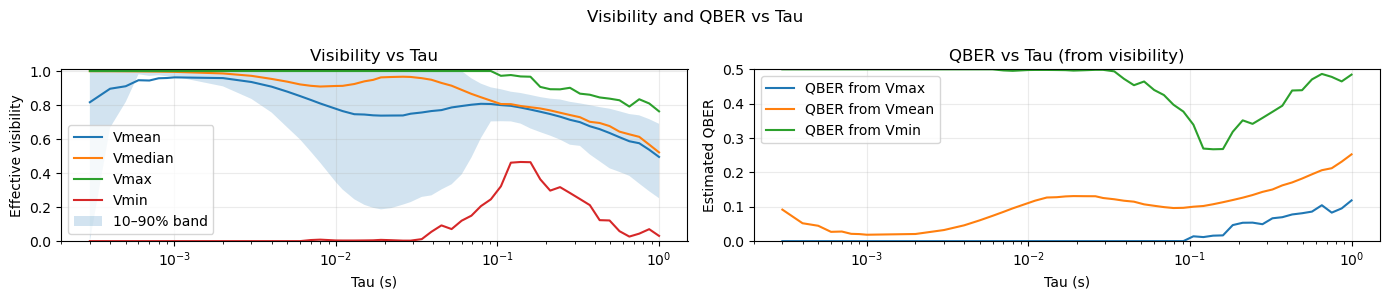

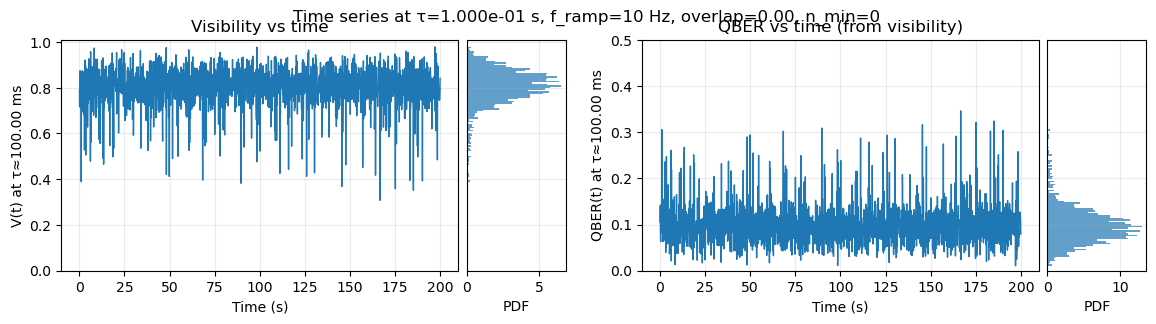

[Selected tau diagnostics]
{'dt': 0.0001, 'K_samples': 1000, 'S_samples': 1000, 'tau_eff_s': 0.1, 'step_eff_s': 0.1, 'n_windows_total': 2000, 'n_windows_used': 2000, 'n_phase': 64, 'iters_ab': 8, 'lam_floor': 1e-06, 'n_min_counts': 0.0, 'clip_for_qber': False}
V median: 0.8114176735040669
V mean:   0.8019176027015933
V 10–90%: 0.7120609890023256 … 0.8934005515546178


In [6]:
NNF_10_em2=Vis.AnalyseMeasurement_NewNumba(NNF,10,50,10,1e-4,1,0.10,10,overlap=0,hist_bins=100)

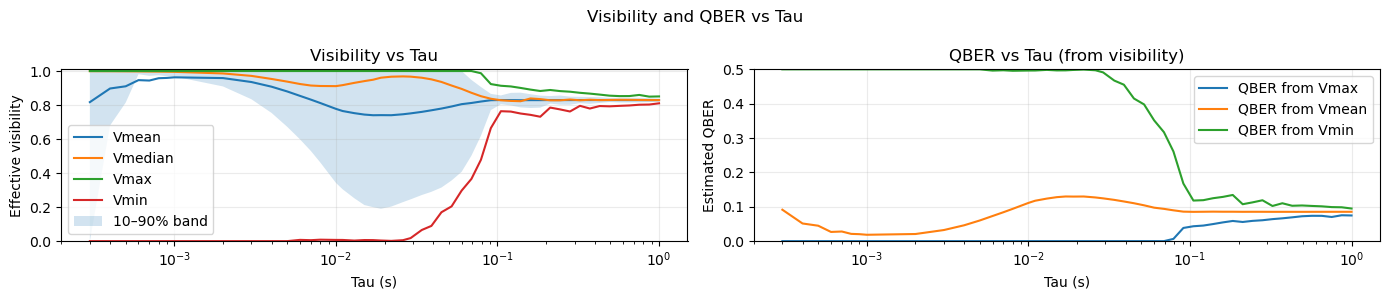

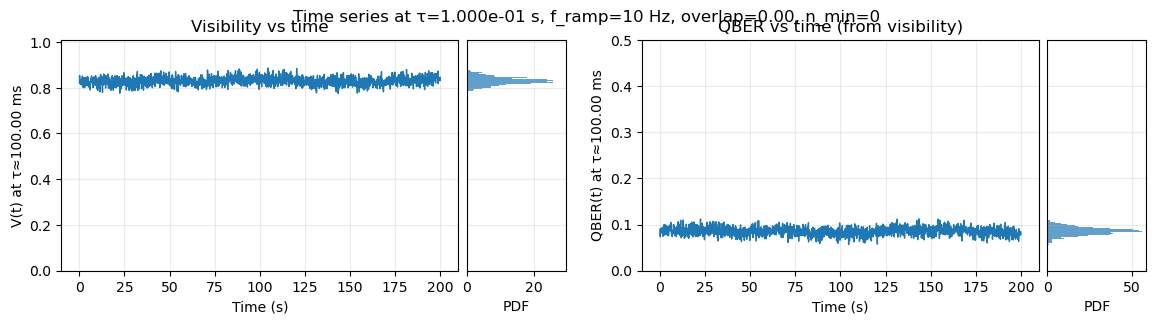

[Selected tau diagnostics]
{'dt': 0.0001, 'K_samples': 1000, 'S_samples': 1000, 'tau_eff_s': 0.1, 'step_eff_s': 0.1, 'n_windows_total': 2000, 'n_windows_used': 2000, 'n_phase': 64, 'iters_ab': 8, 'lam_floor': 1e-06, 'n_min_counts': 0.0, 'clip_for_qber': False}
V median: 0.8294705770465935
V mean:   0.829474636514659
V 10–90%: 0.8073471490616433 … 0.8513474314576265


In [8]:
NNF_10_nm2=Vis.AnalyseMeasurement_NewNumba(NNF,6,50,10,1e-4,1,0.10,10,overlap=0,hist_bins=100)

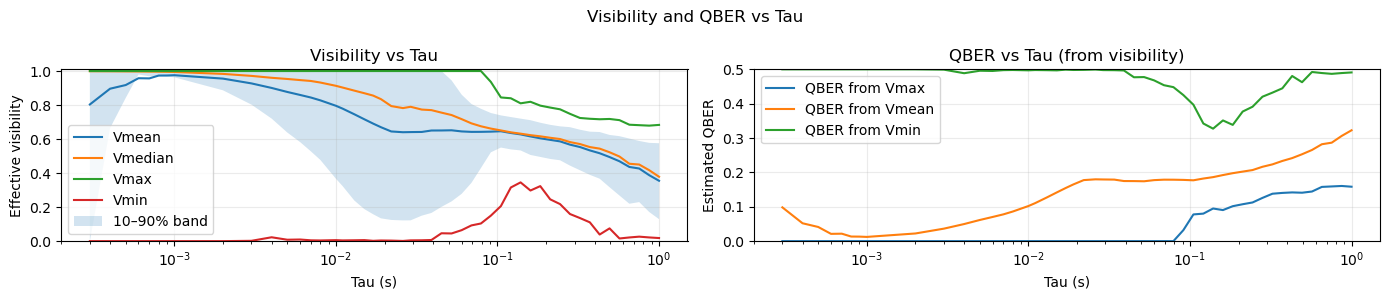

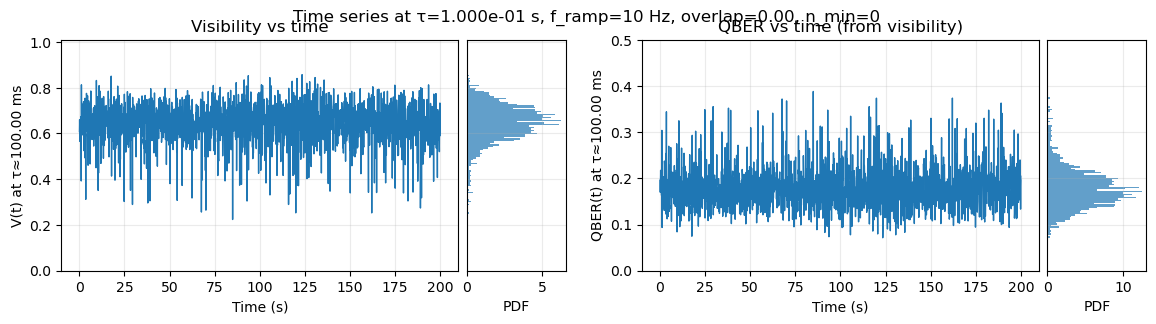

[Selected tau diagnostics]
{'dt': 0.0001, 'K_samples': 1000, 'S_samples': 1000, 'tau_eff_s': 0.1, 'step_eff_s': 0.1, 'n_windows_total': 2000, 'n_windows_used': 2000, 'n_phase': 64, 'iters_ab': 8, 'lam_floor': 1e-06, 'n_min_counts': 0.0, 'clip_for_qber': False}
V median: 0.6520044934342231
V mean:   0.6428079491079166
V 10–90%: 0.5431635154947965 … 0.7428057309235065


In [9]:
NF_10_em2=Vis.AnalyseMeasurement_NewNumba(NF,10,50,10,1e-4,1,0.10,10,overlap=0,hist_bins=100)

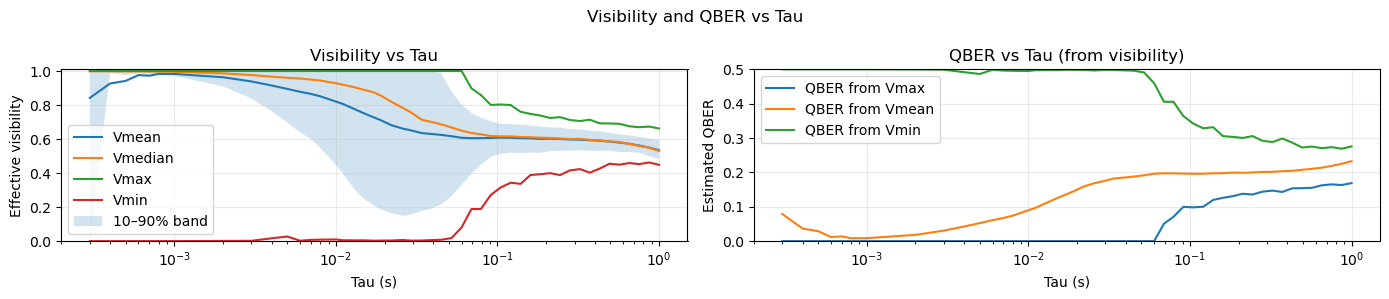

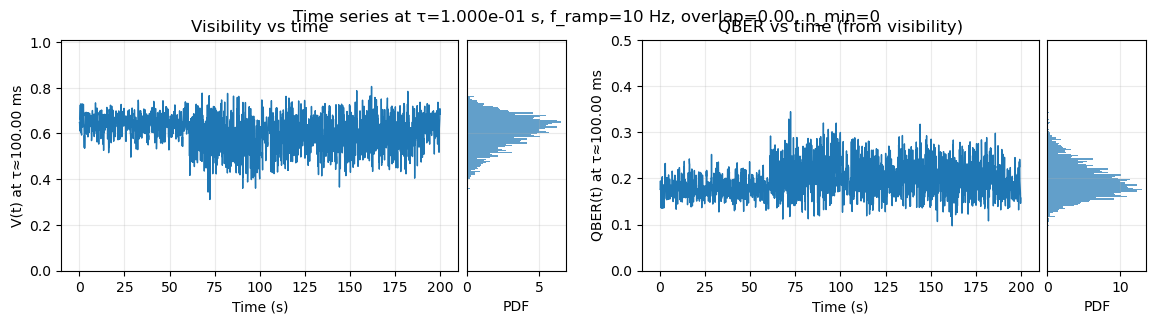

[Selected tau diagnostics]
{'dt': 0.0001, 'K_samples': 1000, 'S_samples': 1000, 'tau_eff_s': 0.1, 'step_eff_s': 0.1, 'n_windows_total': 2000, 'n_windows_used': 2000, 'n_phase': 64, 'iters_ab': 8, 'lam_floor': 1e-06, 'n_min_counts': 0.0, 'clip_for_qber': False}
V median: 0.6173752390762808
V mean:   0.6079236146987903
V 10–90%: 0.5068841350947734 … 0.6923508914050129


In [10]:
NF_10_nm2=Vis.AnalyseMeasurement_NewNumba(NF,6,50,10,1e-4,1,0.10,10,overlap=0,hist_bins=100)

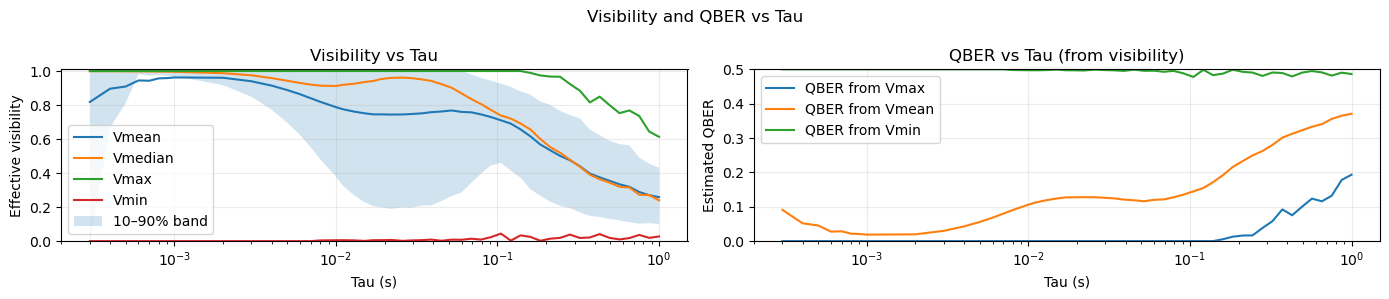

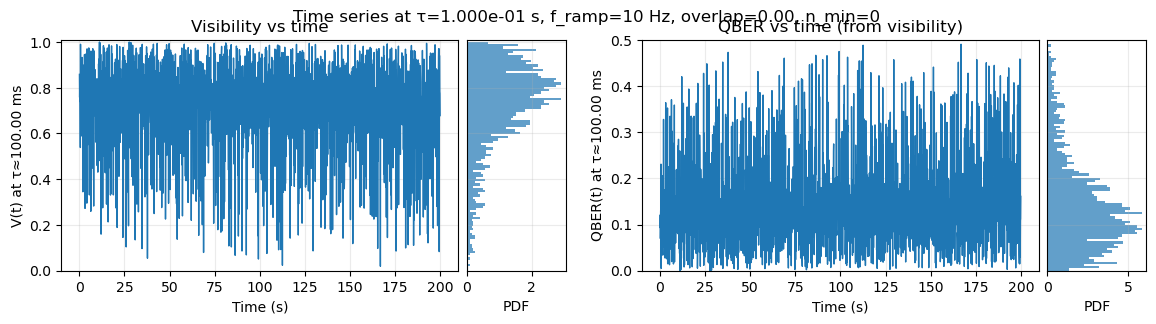

[Selected tau diagnostics]
{'dt': 0.0001, 'K_samples': 1000, 'S_samples': 1000, 'tau_eff_s': 0.1, 'step_eff_s': 0.1, 'n_windows_total': 2000, 'n_windows_used': 2000, 'n_phase': 64, 'iters_ab': 8, 'lam_floor': 1e-06, 'n_min_counts': 0.0, 'clip_for_qber': False}
V median: 0.7518968286014889
V mean:   0.713263105822246
V 10–90%: 0.420177621650891 … 0.9299504128253168


In [11]:
MNF_10_em2=Vis.AnalyseMeasurement_NewNumba(MNF,10,50,10,1e-4,1,0.10,10,overlap=0,hist_bins=100)

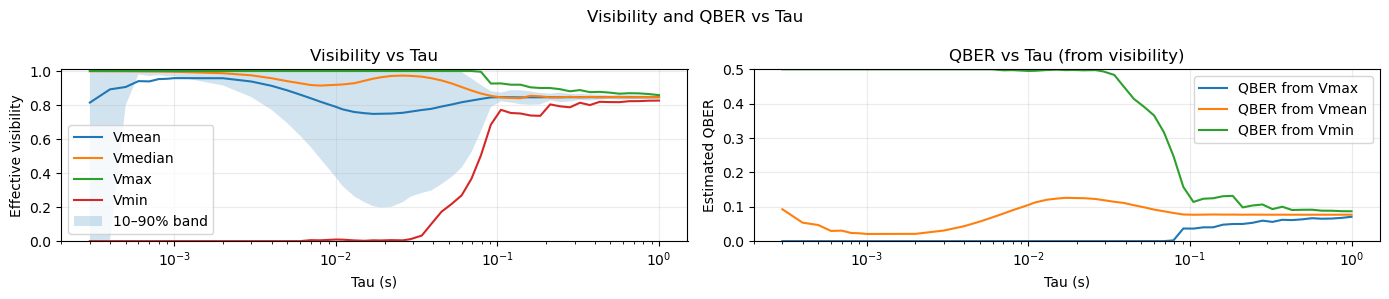

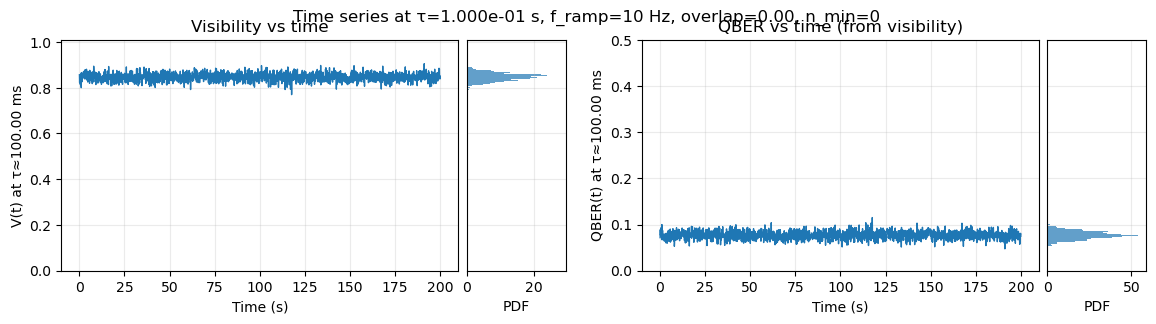

[Selected tau diagnostics]
{'dt': 0.0001, 'K_samples': 1000, 'S_samples': 1000, 'tau_eff_s': 0.1, 'step_eff_s': 0.1, 'n_windows_total': 2000, 'n_windows_used': 2000, 'n_phase': 64, 'iters_ab': 8, 'lam_floor': 1e-06, 'n_min_counts': 0.0, 'clip_for_qber': False}
V median: 0.8467198982327466
V mean:   0.8463182783377834
V 10–90%: 0.8247270429165091 … 0.8682712923706145


In [12]:
MNF_10_nm2=Vis.AnalyseMeasurement_NewNumba(MNF,6,50,10,1e-4,1,0.10,10,overlap=0,hist_bins=100)

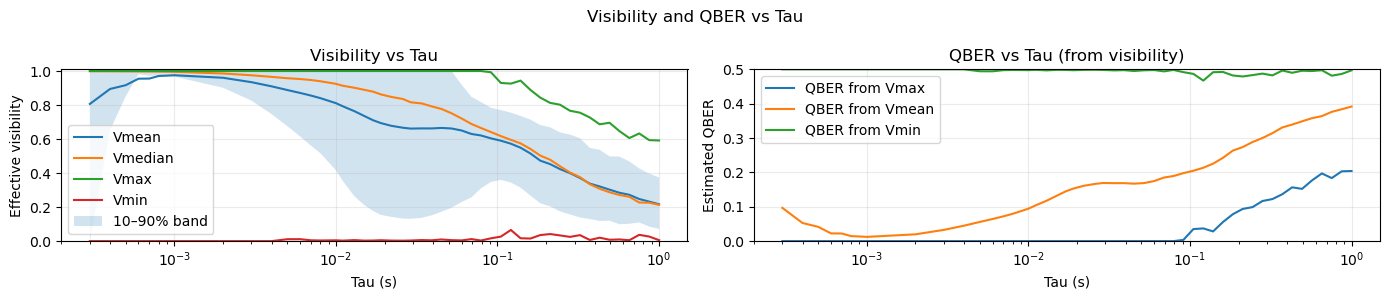

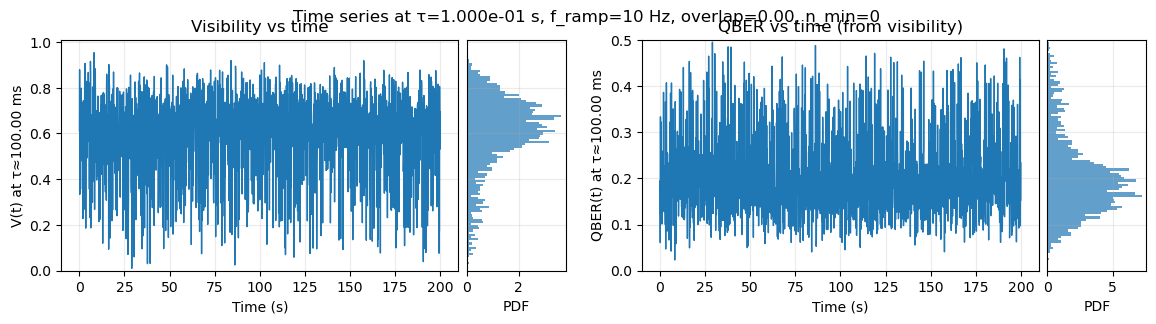

[Selected tau diagnostics]
{'dt': 0.0001, 'K_samples': 1000, 'S_samples': 1000, 'tau_eff_s': 0.1, 'step_eff_s': 0.1, 'n_windows_total': 2000, 'n_windows_used': 2000, 'n_phase': 64, 'iters_ab': 8, 'lam_floor': 1e-06, 'n_min_counts': 0.0, 'clip_for_qber': False}
V median: 0.6230003658002472
V mean:   0.5944762924463244
V 10–90%: 0.33961824656570017 … 0.7791641135839983


In [13]:
MF_10_em2=Vis.AnalyseMeasurement_NewNumba(MF,10,50,10,1e-4,1,0.10,10,overlap=0,hist_bins=100)

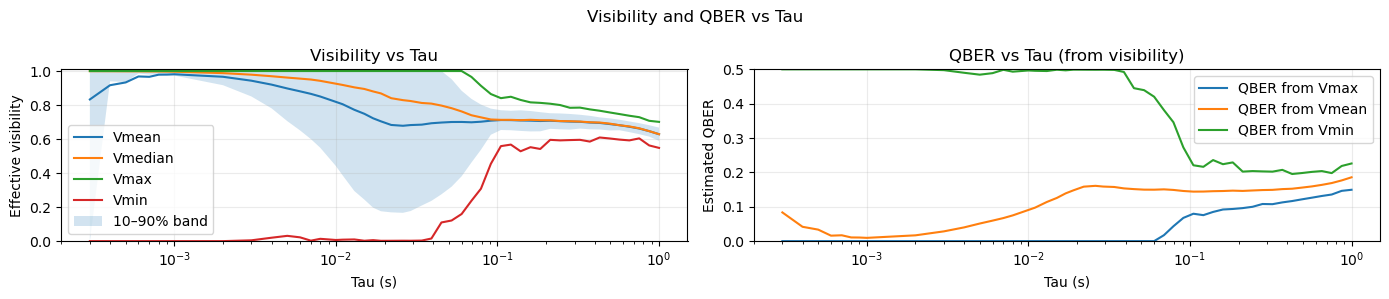

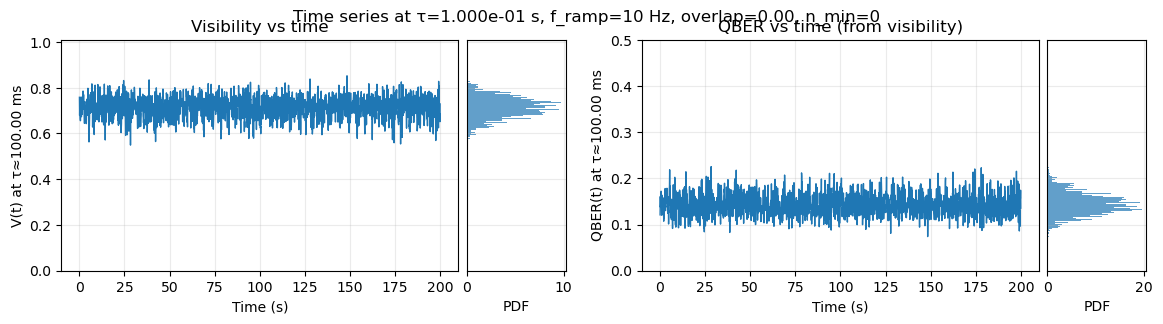

[Selected tau diagnostics]
{'dt': 0.0001, 'K_samples': 1000, 'S_samples': 1000, 'tau_eff_s': 0.1, 'step_eff_s': 0.1, 'n_windows_total': 2000, 'n_windows_used': 2000, 'n_phase': 64, 'iters_ab': 8, 'lam_floor': 1e-06, 'n_min_counts': 0.0, 'clip_for_qber': False}
V median: 0.7136324368082165
V mean:   0.7111218224003476
V 10–90%: 0.6485926383624456 … 0.7702268366936899


In [14]:
MF_10_nm2=Vis.AnalyseMeasurement_NewNumba(MF,6,50,10,1e-4,1,0.10,10,overlap=0,hist_bins=100)

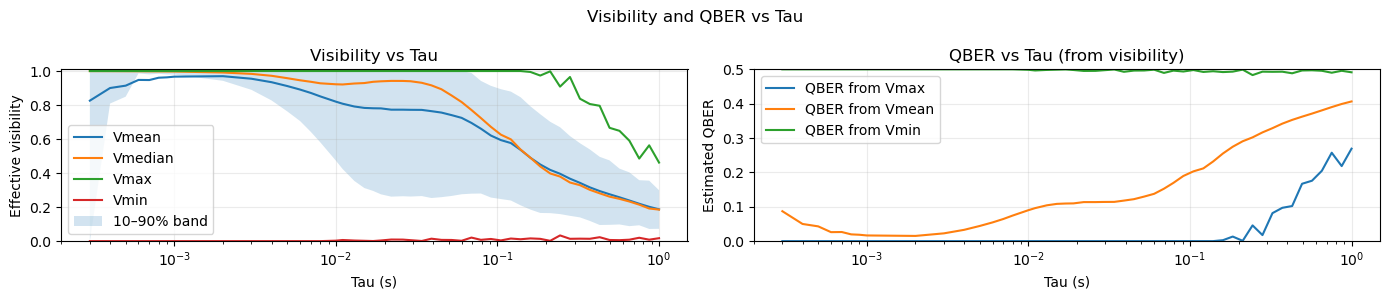

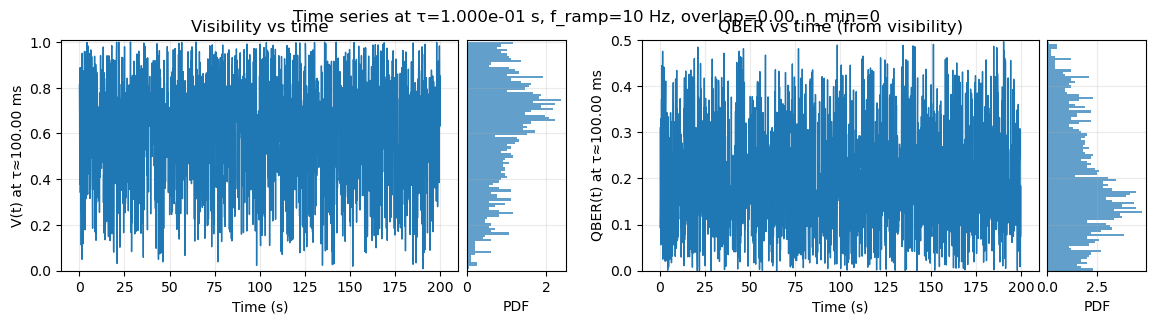

[Selected tau diagnostics]
{'dt': 0.0001, 'K_samples': 1000, 'S_samples': 1000, 'tau_eff_s': 0.1, 'step_eff_s': 0.1, 'n_windows_total': 2000, 'n_windows_used': 2000, 'n_phase': 64, 'iters_ab': 8, 'lam_floor': 1e-06, 'n_min_counts': 0.0, 'clip_for_qber': False}
V median: 0.6512824323921007
V mean:   0.6047459459955291
V 10–90%: 0.24970540446470774 … 0.8952156282523316


In [15]:
DNF_10_em2=Vis.AnalyseMeasurement_NewNumba(DNF,10,50,10,1e-4,1,0.10,10,overlap=0,hist_bins=100)

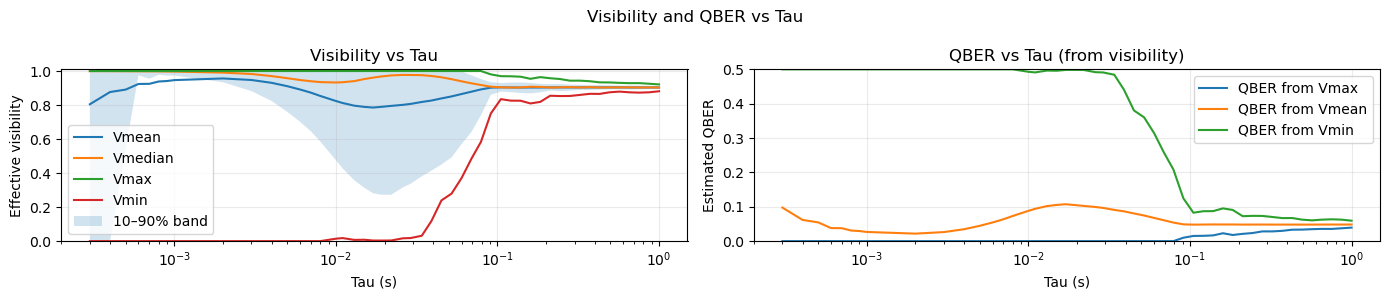

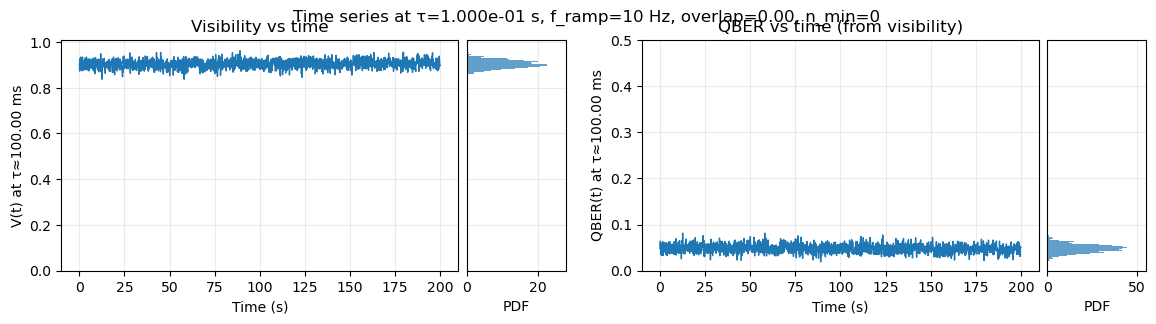

[Selected tau diagnostics]
{'dt': 0.0001, 'K_samples': 1000, 'S_samples': 1000, 'tau_eff_s': 0.1, 'step_eff_s': 0.1, 'n_windows_total': 2000, 'n_windows_used': 2000, 'n_phase': 64, 'iters_ab': 8, 'lam_floor': 1e-06, 'n_min_counts': 0.0, 'clip_for_qber': False}
V median: 0.9038675350317273
V mean:   0.903756321010849
V 10–90%: 0.8811217518507576 … 0.9264631441576898


In [16]:
DNF_10_nm2=Vis.AnalyseMeasurement_NewNumba(DNF,6,50,10,1e-4,1,0.10,10,overlap=0,hist_bins=100)

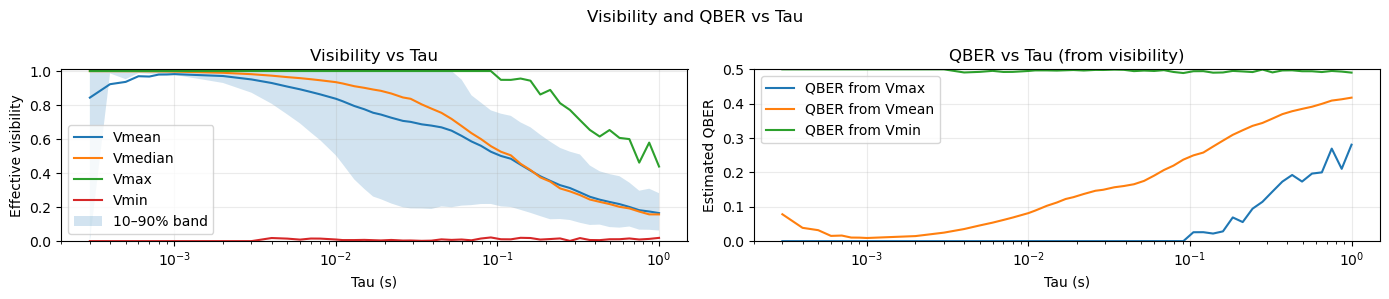

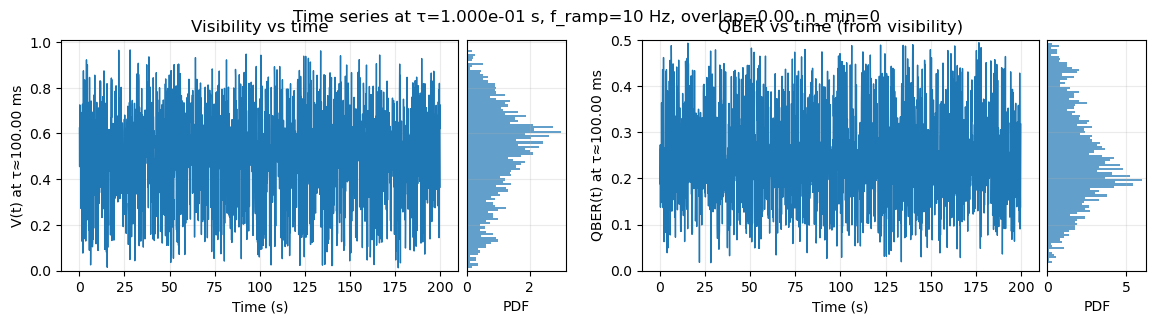

[Selected tau diagnostics]
{'dt': 0.0001, 'K_samples': 1000, 'S_samples': 1000, 'tau_eff_s': 0.1, 'step_eff_s': 0.1, 'n_windows_total': 2000, 'n_windows_used': 2000, 'n_phase': 64, 'iters_ab': 8, 'lam_floor': 1e-06, 'n_min_counts': 0.0, 'clip_for_qber': False}
V median: 0.5352400206794088
V mean:   0.5099147165081142
V 10–90%: 0.2115112333725286 … 0.766855728785583


In [17]:
DF_10_em2=Vis.AnalyseMeasurement_NewNumba(DF,11,50,10,1e-4,1,0.10,10,overlap=0,hist_bins=100)

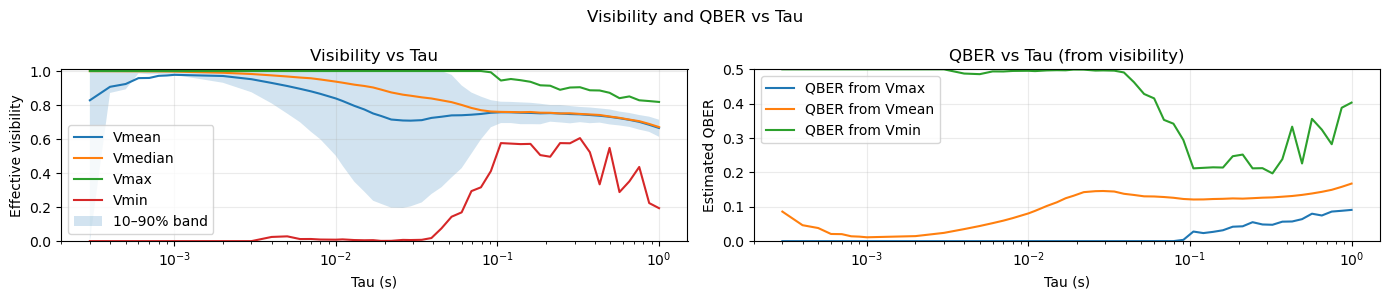

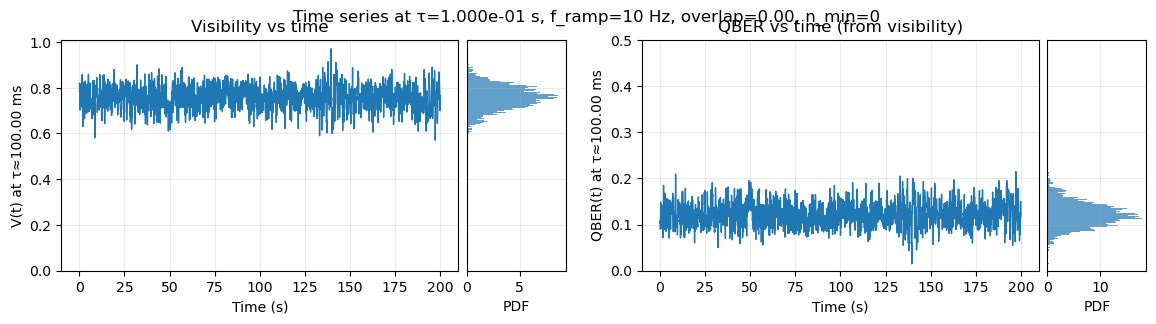

[Selected tau diagnostics]
{'dt': 0.0001, 'K_samples': 1000, 'S_samples': 1000, 'tau_eff_s': 0.1, 'step_eff_s': 0.1, 'n_windows_total': 2000, 'n_windows_used': 2000, 'n_phase': 64, 'iters_ab': 8, 'lam_floor': 1e-06, 'n_min_counts': 0.0, 'clip_for_qber': False}
V median: 0.7588426739014056
V mean:   0.7572084851470738
V 10–90%: 0.6916670109404298 … 0.8217405121056561


In [18]:
DF_10_nm2=Vis.AnalyseMeasurement_NewNumba(DF,7,50,10,1e-4,1,0.10,10,overlap=0,hist_bins=100)

In [21]:
np.save('NNF_10_em_Numba.npy',NNF_10_em2[1])
np.save('NNF_10_nm_Numba.npy',NNF_10_nm2[1])
np.save('NF_10_em_Numba.npy',NF_10_em2[1])
np.save('NF_10_nm_Numba.npy',NF_10_nm2[1])

In [71]:
np.save('NNF_10_em_Numba.npy', np.array(NNF_10_em2, dtype=object), allow_pickle=True)
np.save('NNF_10_nm_Numba.npy', np.array(NNF_10_nm2, dtype=object), allow_pickle=True)
np.save('NF_10_em_Numba.npy', np.array(NF_10_em2, dtype=object), allow_pickle=True)
np.save('NF_10_nm_Numba.npy', np.array(NF_10_nm2, dtype=object), allow_pickle=True)

In [23]:
np.save('MNF_10_em_Numba.npy',MNF_10_em2[1])
np.save('MNF_10_nm_Numba.npy',MNF_10_nm2[1])
np.save('MF_10_em_Numba.npy',MF_10_em2[1])
np.save('MF_10_nm_Numba.npy',MF_10_nm2[1])

In [73]:
np.save('MNF_10_em_Numba.npy', np.array(MNF_10_em2, dtype=object), allow_pickle=True)
np.save('MNF_10_nm_Numba.npy', np.array(MNF_10_nm2, dtype=object), allow_pickle=True)
np.save('MF_10_em_Numba.npy', np.array(MF_10_em2, dtype=object), allow_pickle=True)
np.save('MF_10_nm_Numba.npy', np.array(MF_10_nm2, dtype=object), allow_pickle=True)

In [25]:
np.save('DNF_10_em_Numba.npy',DNF_10_em2[1])
np.save('DNF_10_nm_Numba.npy',DNF_10_nm2[1])
np.save('DF_10_em_Numba.npy',DF_10_em2[1])
np.save('DF_10_nm_Numba.npy',DF_10_nm2[1])

In [75]:
np.save('DNF_10_em_Numba.npy', np.array(DNF_10_em2, dtype=object), allow_pickle=True)
np.save('DNF_10_nm_Numba.npy', np.array(DNF_10_nm2, dtype=object), allow_pickle=True)
np.save('DF_10_em_Numba.npy', np.array(DF_10_em2, dtype=object), allow_pickle=True)
np.save('DF_10_nm_Numba.npy', np.array(DF_10_nm2, dtype=object), allow_pickle=True)

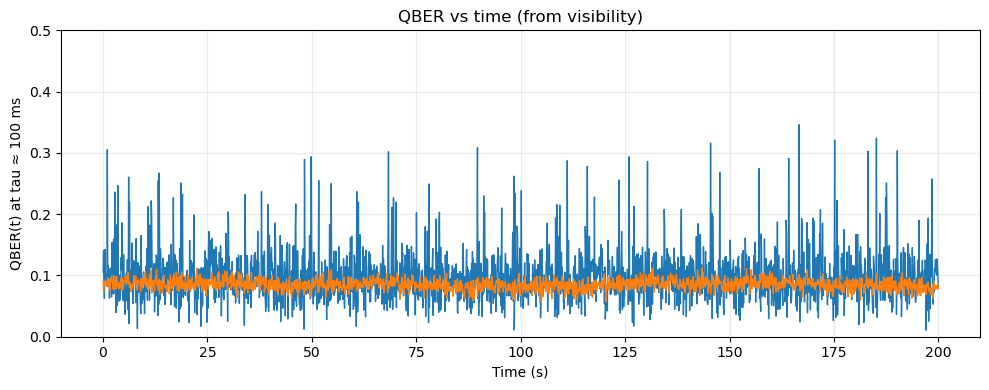

In [27]:
plt.figure(figsize=(10, 4))
plt.plot(NNF_10_em2[0][2][0], NNF_10_em2[0][2][1], linewidth=1)
plt.plot(NNF_10_nm2[0][2][0], NNF_10_nm2[0][2][1], linewidth=1)
plt.ylim(0, 0.5)
plt.xlabel("Time (s)")
plt.ylabel(f"QBER(t) at tau ≈ 100 ms")
plt.title("QBER vs time (from visibility)")
plt.grid(True, alpha=0.25)
plt.tight_layout()
plt.show()

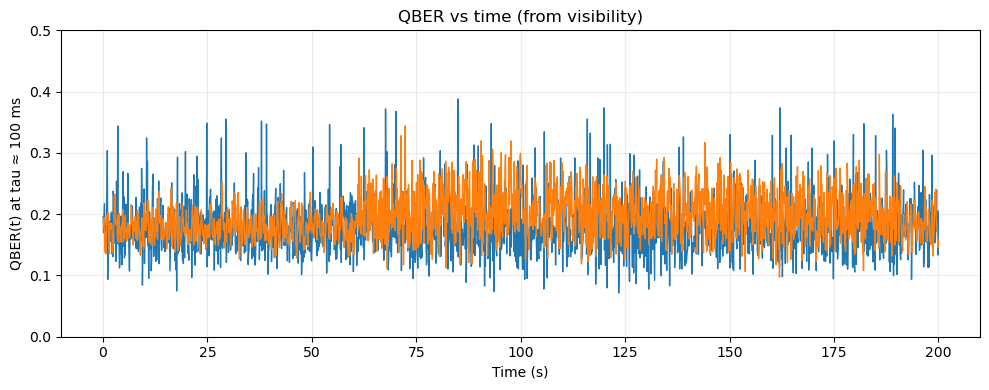

In [29]:
plt.figure(figsize=(10, 4))
plt.plot(NF_10_em2[0][2][0], NF_10_em2[0][2][1], linewidth=1)
plt.plot(NF_10_nm2[0][2][0], NF_10_nm2[0][2][1], linewidth=1)
plt.ylim(0, 0.5)
plt.xlabel("Time (s)")
plt.ylabel(f"QBER(t) at tau ≈ 100 ms")
plt.title("QBER vs time (from visibility)")
plt.grid(True, alpha=0.25)
plt.tight_layout()
plt.show()

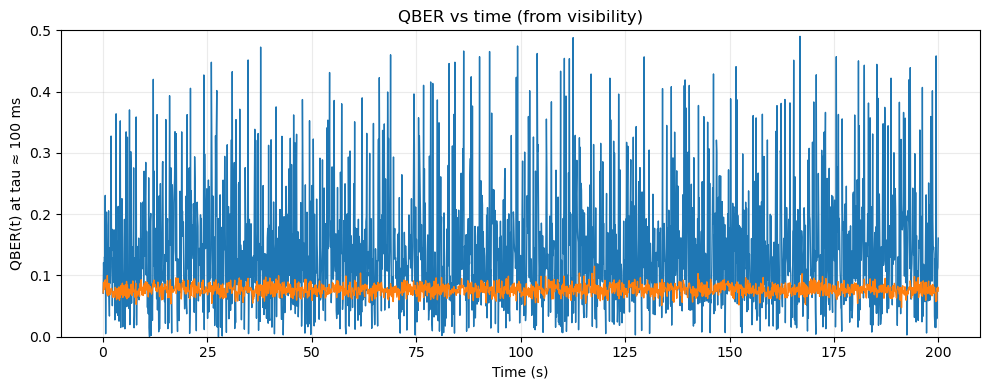

In [31]:
plt.figure(figsize=(10, 4))
plt.plot(MNF_10_em2[0][2][0], MNF_10_em2[0][2][1], linewidth=1)
plt.plot(MNF_10_nm2[0][2][0], MNF_10_nm2[0][2][1], linewidth=1)
plt.ylim(0, 0.5)
plt.xlabel("Time (s)")
plt.ylabel(f"QBER(t) at tau ≈ 100 ms")
plt.title("QBER vs time (from visibility)")
plt.grid(True, alpha=0.25)
plt.tight_layout()
plt.show()

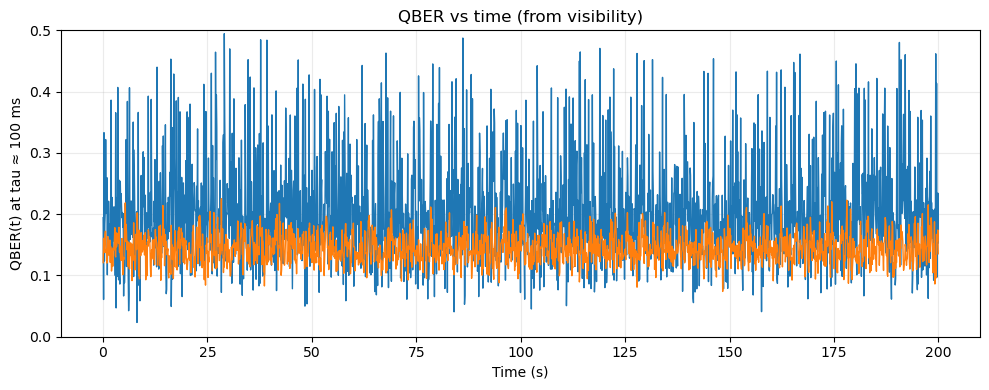

In [33]:
plt.figure(figsize=(10, 4))
plt.plot(MF_10_em2[0][2][0], MF_10_em2[0][2][1], linewidth=1)
plt.plot(MF_10_nm2[0][2][0], MF_10_nm2[0][2][1], linewidth=1)
plt.ylim(0, 0.5)
plt.xlabel("Time (s)")
plt.ylabel(f"QBER(t) at tau ≈ 100 ms")
plt.title("QBER vs time (from visibility)")
plt.grid(True, alpha=0.25)
plt.tight_layout()
plt.show()

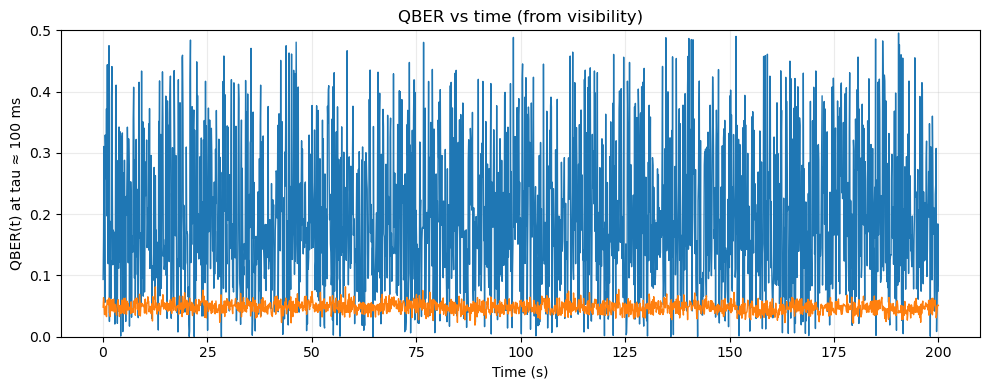

In [35]:
plt.figure(figsize=(10, 4))
plt.plot(DNF_10_em2[0][2][0], DNF_10_em2[0][2][1], linewidth=1)
plt.plot(DNF_10_nm2[0][2][0], DNF_10_nm2[0][2][1], linewidth=1)
plt.ylim(0, 0.5)
plt.xlabel("Time (s)")
plt.ylabel(f"QBER(t) at tau ≈ 100 ms")
plt.title("QBER vs time (from visibility)")
plt.grid(True, alpha=0.25)
plt.tight_layout()
plt.show()

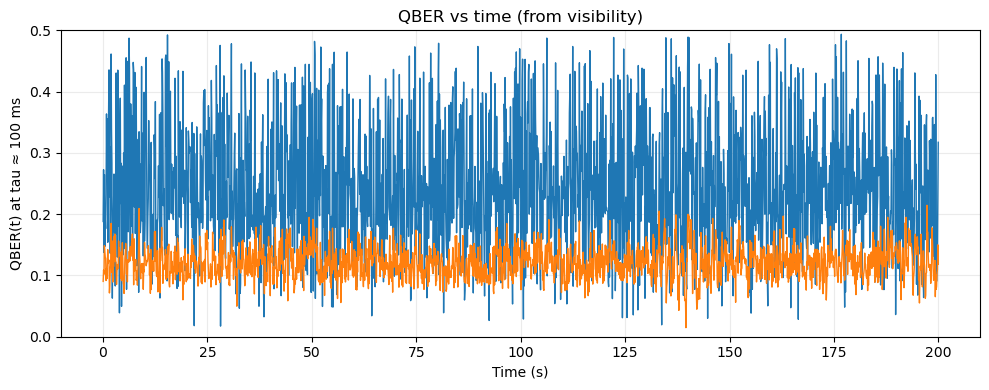

In [37]:
plt.figure(figsize=(10, 4))
plt.plot(DF_10_em2[0][2][0], DF_10_em2[0][2][1], linewidth=1)
plt.plot(DF_10_nm2[0][2][0], DF_10_nm2[0][2][1], linewidth=1)
plt.ylim(0, 0.5)
plt.xlabel("Time (s)")
plt.ylabel(f"QBER(t) at tau ≈ 100 ms")
plt.title("QBER vs time (from visibility)")
plt.grid(True, alpha=0.25)
plt.tight_layout()
plt.show()

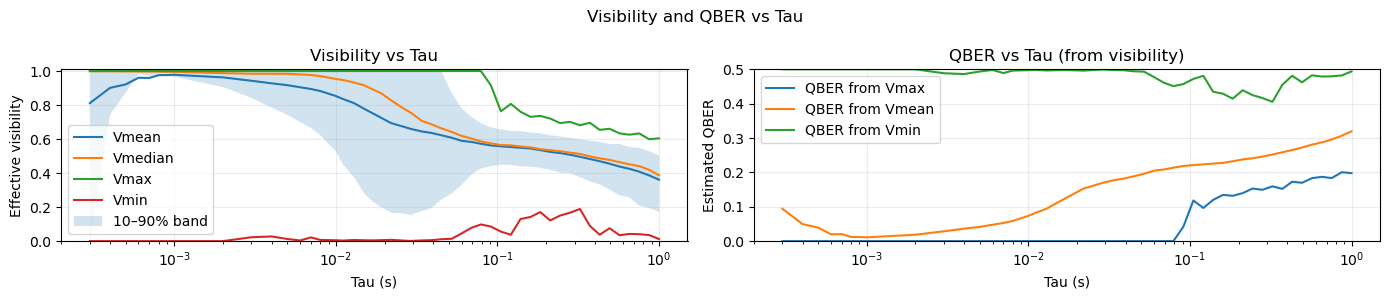

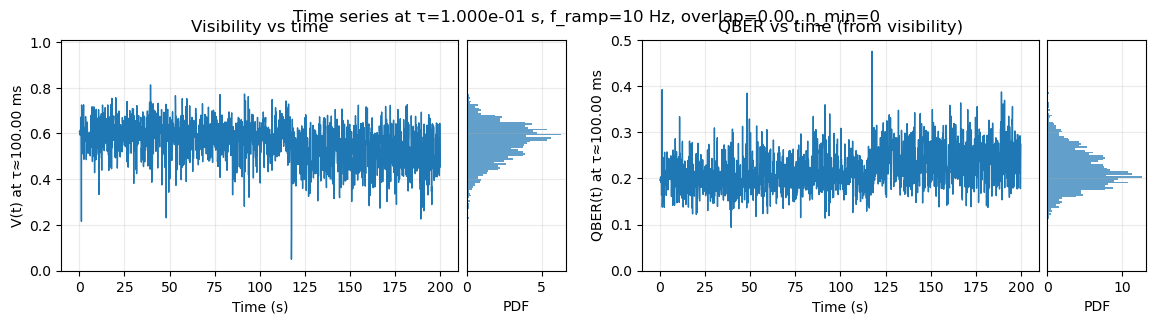

[Selected tau diagnostics]
{'dt': 0.0001, 'K_samples': 1000, 'S_samples': 1000, 'tau_eff_s': 0.1, 'step_eff_s': 0.1, 'n_windows_total': 2000, 'n_windows_used': 2000, 'n_phase': 64, 'iters_ab': 8, 'lam_floor': 1e-06, 'n_min_counts': 0.0, 'clip_for_qber': False}
V median: 0.5701696254529411
V mean:   0.558788029249118
V 10–90%: 0.44475378193838644 … 0.6588348613173167


In [39]:
NL_10_em2=Vis.AnalyseMeasurement_NewNumba(NL,10,50,10,1e-4,1,0.10,10,overlap=0,hist_bins=100)

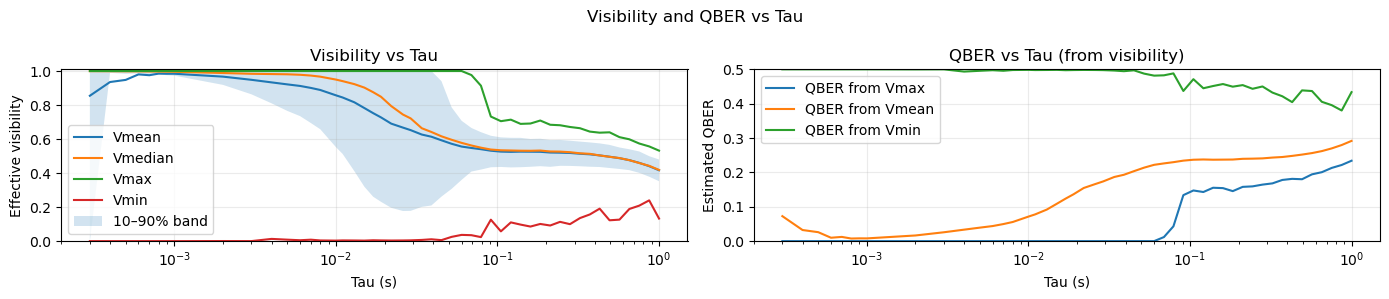

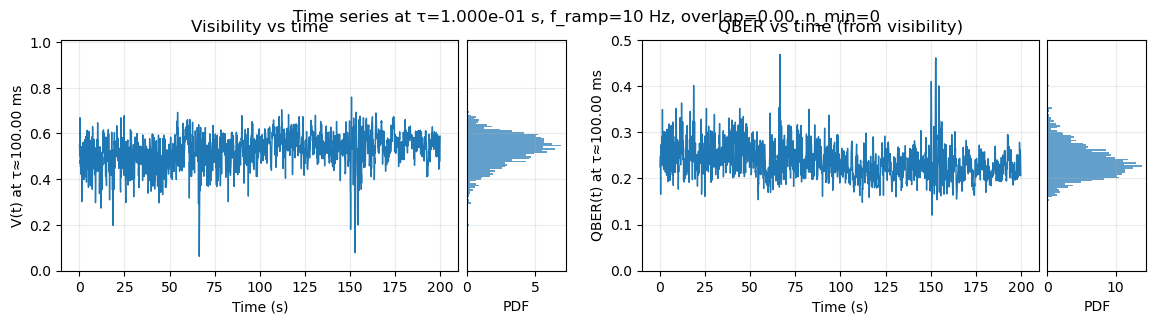

[Selected tau diagnostics]
{'dt': 0.0001, 'K_samples': 1000, 'S_samples': 1000, 'tau_eff_s': 0.1, 'step_eff_s': 0.1, 'n_windows_total': 2000, 'n_windows_used': 2000, 'n_phase': 64, 'iters_ab': 8, 'lam_floor': 1e-06, 'n_min_counts': 0.0, 'clip_for_qber': False}
V median: 0.5348110828085194
V mean:   0.5268793134393607
V 10–90%: 0.43335618684847793 … 0.6071998605539489


In [40]:
NL_10_nm2=Vis.AnalyseMeasurement_NewNumba(NL,6,50,10,1e-4,1,0.10,10,overlap=0,hist_bins=100)

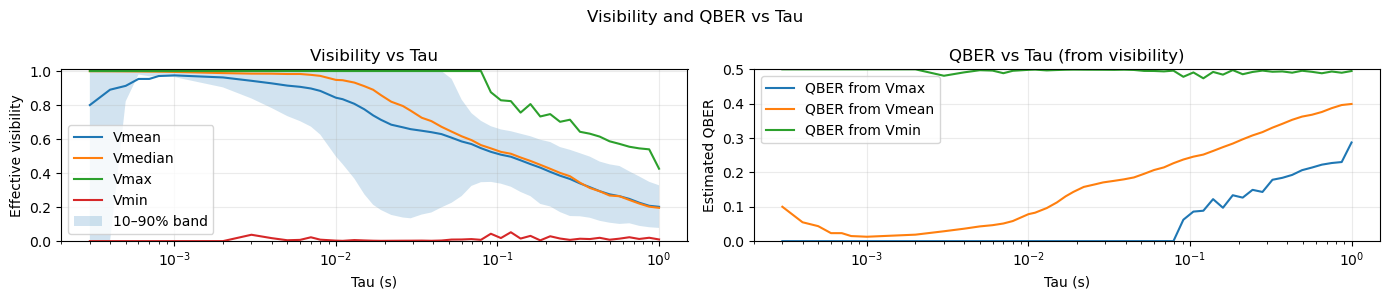

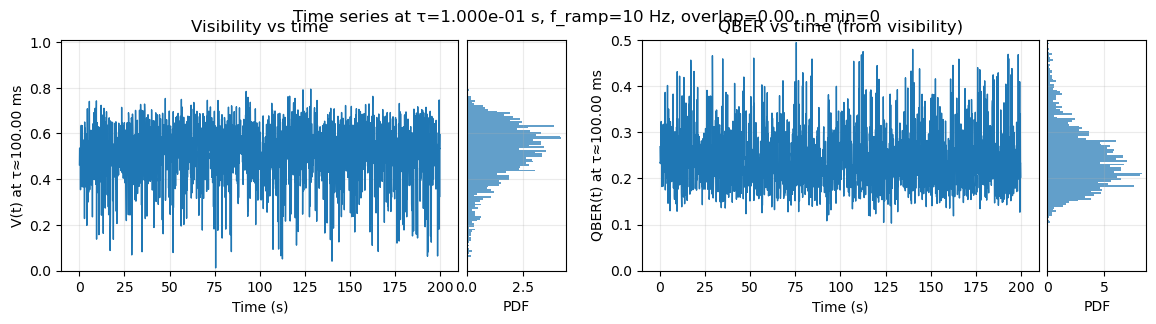

[Selected tau diagnostics]
{'dt': 0.0001, 'K_samples': 1000, 'S_samples': 1000, 'tau_eff_s': 0.1, 'step_eff_s': 0.1, 'n_windows_total': 2000, 'n_windows_used': 2000, 'n_phase': 64, 'iters_ab': 8, 'lam_floor': 1e-06, 'n_min_counts': 0.0, 'clip_for_qber': False}
V median: 0.5289367417630149
V mean:   0.5133627066305848
V 10–90%: 0.3463914886332248 … 0.6629988654635585


In [41]:
NLF_10_em2=Vis.AnalyseMeasurement_NewNumba(NLF,10,50,10,1e-4,1,0.10,10,overlap=0,hist_bins=100)

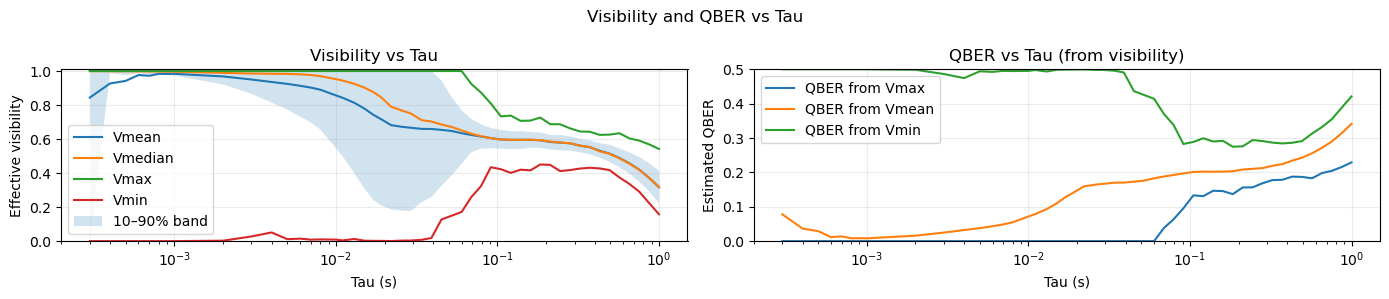

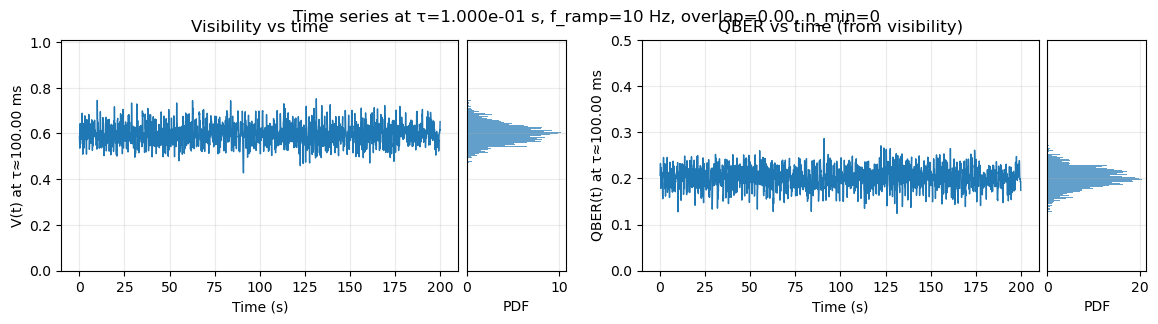

[Selected tau diagnostics]
{'dt': 0.0001, 'K_samples': 1000, 'S_samples': 1000, 'tau_eff_s': 0.1, 'step_eff_s': 0.1, 'n_windows_total': 2000, 'n_windows_used': 2000, 'n_phase': 64, 'iters_ab': 8, 'lam_floor': 1e-06, 'n_min_counts': 0.0, 'clip_for_qber': False}
V median: 0.5983536927053927
V mean:   0.5983110302969032
V 10–90%: 0.5427984053198504 … 0.6568847272351874


In [42]:
NLF_10_nm2=Vis.AnalyseMeasurement_NewNumba(NLF,6,50,10,1e-4,1,0.10,10,overlap=0,hist_bins=100)

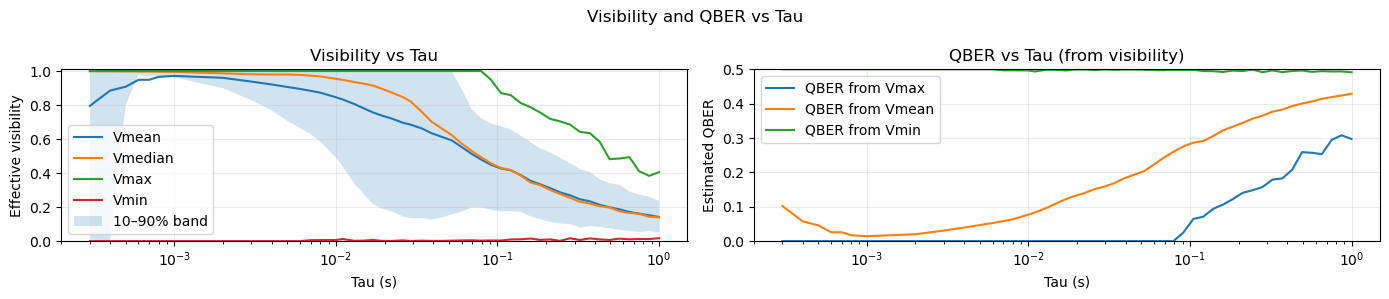

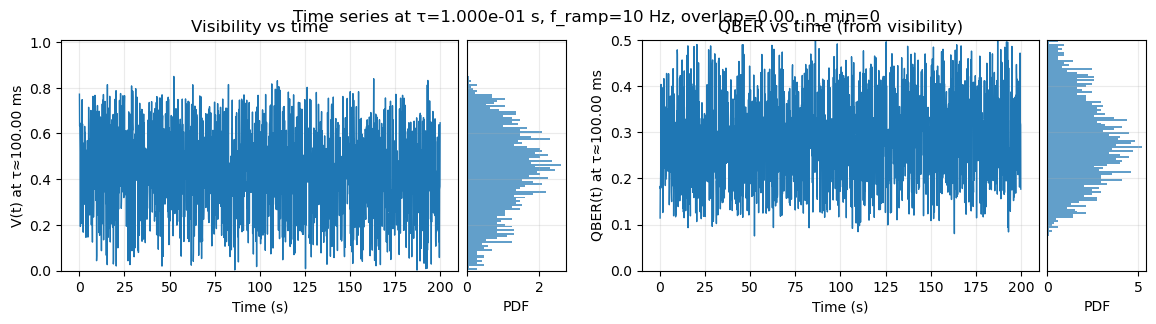

[Selected tau diagnostics]
{'dt': 0.0001, 'K_samples': 1000, 'S_samples': 1000, 'tau_eff_s': 0.1, 'step_eff_s': 0.1, 'n_windows_total': 2000, 'n_windows_used': 2000, 'n_phase': 64, 'iters_ab': 8, 'lam_floor': 1e-06, 'n_min_counts': 0.0, 'clip_for_qber': False}
V median: 0.4459267863928267
V mean:   0.435717417693635
V 10–90%: 0.1754486447663536 … 0.6744231762819021


In [43]:
NLVF_10_em2=Vis.AnalyseMeasurement_NewNumba(NLVF,10,50,10,1e-4,1,0.10,10,overlap=0,hist_bins=100)

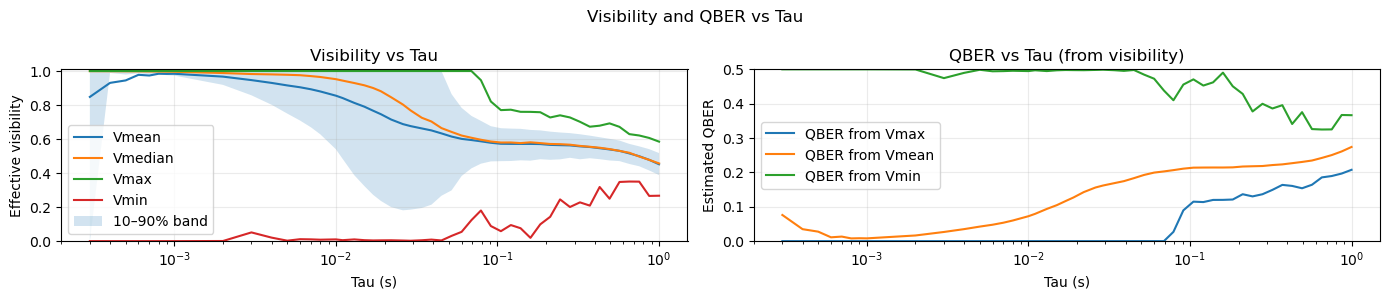

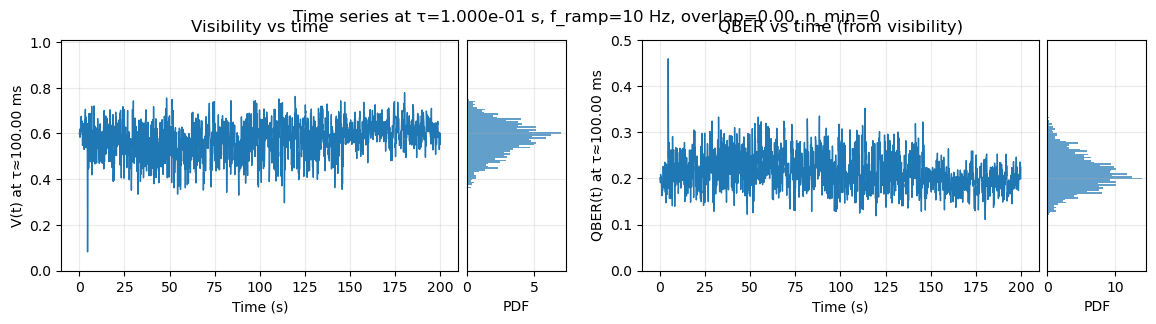

[Selected tau diagnostics]
{'dt': 0.0001, 'K_samples': 1000, 'S_samples': 1000, 'tau_eff_s': 0.1, 'step_eff_s': 0.1, 'n_windows_total': 2000, 'n_windows_used': 2000, 'n_phase': 64, 'iters_ab': 8, 'lam_floor': 1e-06, 'n_min_counts': 0.0, 'clip_for_qber': False}
V median: 0.5806395521255985
V mean:   0.5733010849364344
V 10–90%: 0.4713189494685382 … 0.6660776258571436


In [44]:
NLVF_10_nm2=Vis.AnalyseMeasurement_NewNumba(NLVF,6,50,10,1e-4,1,0.10,10,overlap=0,hist_bins=100)

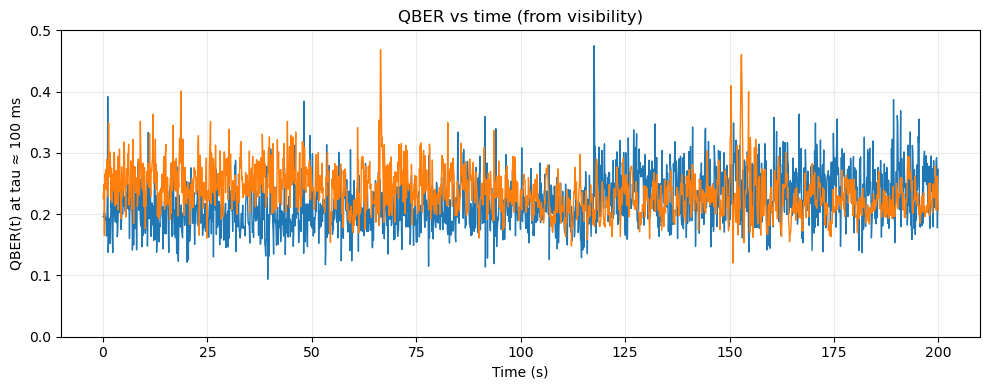

In [45]:
plt.figure(figsize=(10, 4))
plt.plot(NL_10_em2[0][2][0], NL_10_em2[0][2][1], linewidth=1)
plt.plot(NL_10_nm2[0][2][0], NL_10_nm2[0][2][1], linewidth=1)
plt.ylim(0, 0.5)
plt.xlabel("Time (s)")
plt.ylabel(f"QBER(t) at tau ≈ 100 ms")
plt.title("QBER vs time (from visibility)")
plt.grid(True, alpha=0.25)
plt.tight_layout()
plt.show()

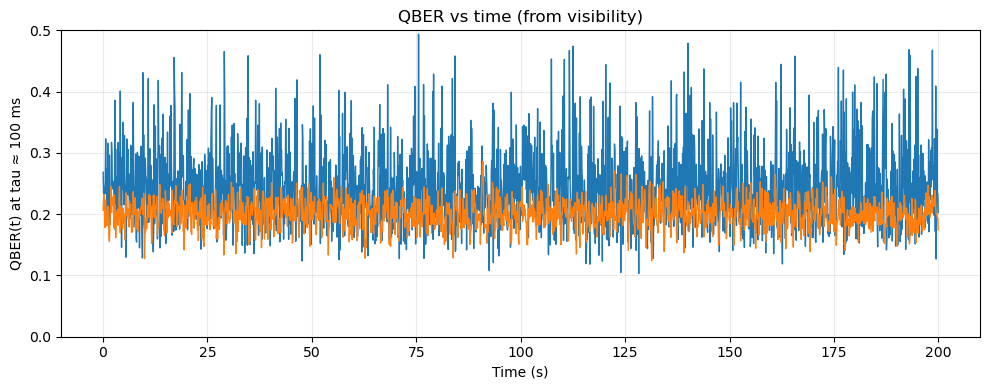

In [46]:
plt.figure(figsize=(10, 4))
plt.plot(NLF_10_em2[0][2][0], NLF_10_em2[0][2][1], linewidth=1)
plt.plot(NLF_10_nm2[0][2][0], NLF_10_nm2[0][2][1], linewidth=1)
plt.ylim(0, 0.5)
plt.xlabel("Time (s)")
plt.ylabel(f"QBER(t) at tau ≈ 100 ms")
plt.title("QBER vs time (from visibility)")
plt.grid(True, alpha=0.25)
plt.tight_layout()
plt.show()

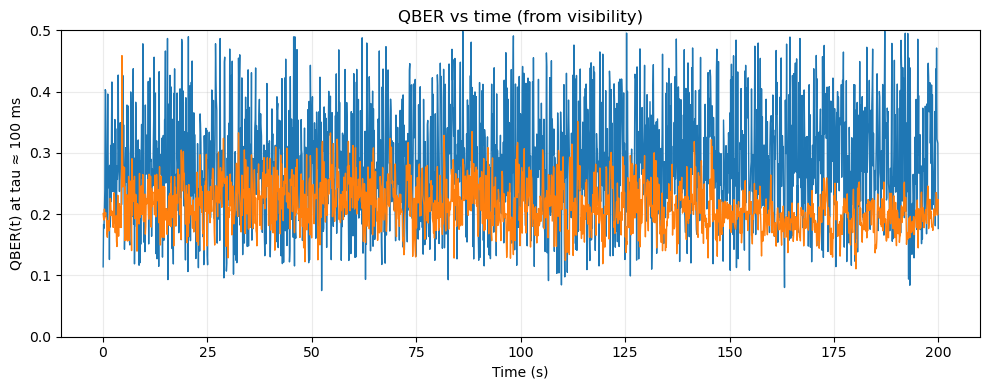

In [47]:
plt.figure(figsize=(10, 4))
plt.plot(NLVF_10_em2[0][2][0], NLVF_10_em2[0][2][1], linewidth=1)
plt.plot(NLVF_10_nm2[0][2][0], NLVF_10_nm2[0][2][1], linewidth=1)
plt.ylim(0, 0.5)
plt.xlabel("Time (s)")
plt.ylabel(f"QBER(t) at tau ≈ 100 ms")
plt.title("QBER vs time (from visibility)")
plt.grid(True, alpha=0.25)
plt.tight_layout()
plt.show()

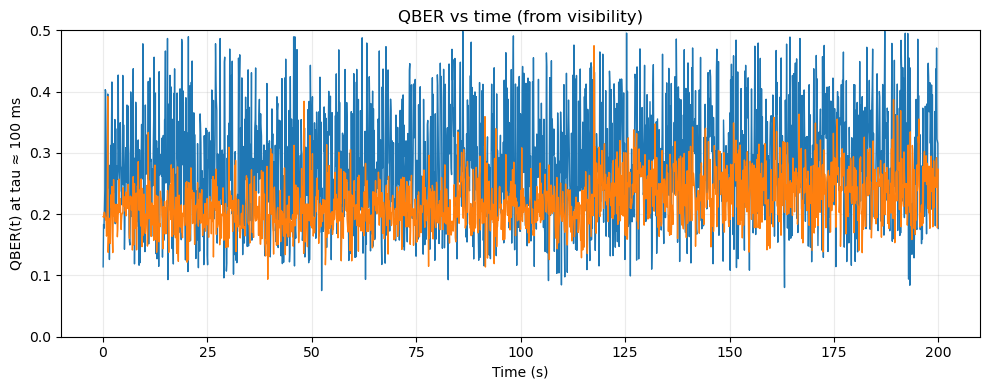

In [69]:
plt.figure(figsize=(10, 4))
plt.plot(NLVF_10_em2[0][2][0], NLVF_10_em2[0][2][1], linewidth=1)
plt.plot(NL_10_em2[0][2][0], NL_10_em2[0][2][1], linewidth=1)
plt.ylim(0, 0.5)
plt.xlabel("Time (s)")
plt.ylabel(f"QBER(t) at tau ≈ 100 ms")
plt.title("QBER vs time (from visibility)")
plt.grid(True, alpha=0.25)
plt.tight_layout()
plt.show()

In [67]:
np.save('NLVF_10_em_Numba.npy', np.array(NLVF_10_em2, dtype=object), allow_pickle=True)
np.save('NLVF_10_nm_Numba.npy', np.array(NLVF_10_nm2, dtype=object), allow_pickle=True)
np.save('NLF_10_em_Numba.npy', np.array(NLF_10_em2, dtype=object), allow_pickle=True)
np.save('NLF_10_nm_Numba.npy', np.array(NLF_10_nm2, dtype=object), allow_pickle=True)
np.save('NL_10_em_Numba.npy', np.array(NL_10_em2, dtype=object), allow_pickle=True)
np.save('NL_10_nm_Numba.npy', np.array(NL_10_nm2, dtype=object), allow_pickle=True)